# Exercicio 14 - U-Net para segmentacao simples

Crie imagens sinteticas com circulos ou quadrados e suas mascaras binarias.

Treine uma U-Net para prever a mascara. Use:

- BCEWithLogitsLoss ou Dice Loss;
- Adam;
- batch_size pequeno;
- pelo menos 10 epocas.

Durante o treinamento, salve:
- imagem de entrada;
- mascara verdadeira;
- mascara prevista depois de sigmoid.

## Funções de desenho de círculos e quadrados

In [16]:
import numpy as np

def desenha_quadrado(x0: int,y0: int, raio: int) -> np.array:
    x = np.arange(N)
    y = np.arange(N)
    X, Y = np.meshgrid(x, y)
    Z = np.maximum(np.abs(Y - y0), np.abs(X - x0))
    return (Z <= raio).astype(float)

def desenha_circuferencia(x0: int,y0: int, raio: int):
    x = np.arange(N)
    y = np.arange(N)
    X, Y = np.meshgrid(x, y)
    Z = np.sqrt((Y - y0)**2 + (X - x0)**2)
    return (Z <= raio*raio).astype(float)


## Criar imagens sinteticas 128x128

In [17]:
np.random.seed(42)

def gerar_mascara_imagem(N=128, formas=6):
    # raios possiveis (raioa < r < raiob)
    raioa = 1
    raiob = 5

    mascara = np.zeros((N,N), dtype=float)
    imagem = np.zeros((N,N), dtype=float)

    for f in range(formas):
        # Sorteia aleatoriamente a forma geométrica
        tipo_forma = np.random.choice(['q', 'c'])

        raio = np.random.randint(raioa, raiob)

        # Sorteia o centro (x0, y0)
        x0 = np.random.randint(raio, N - raio)
        y0 = np.random.randint(raio, N - raio)

        intensidade = np.random.uniform(0.0, 255.0)

        forma_atual = desenha_quadrado(x0,y0,raio) if tipo_forma == 'q' else desenha_circuferencia(x0,y0,raio)
        mascara = np.maximum(mascara, forma_atual)
        imagem = np.maximum(imagem, forma_atual * intensidade)

    # adiciona um leve ruído gaussiano na imagem original
    ruido = np.random.normal(0, 0.02, size=(N, N))
    imagem = np.clip(imagem + ruido, 0.0, 255.0)

    return mascara, imagem

# quantas formas geometricas vao ter na imagem
samples = 10
dataset = []
N=128

for _ in range(samples):
    m, img = gerar_mascara_imagem(N)
    dataset.append([m, img])

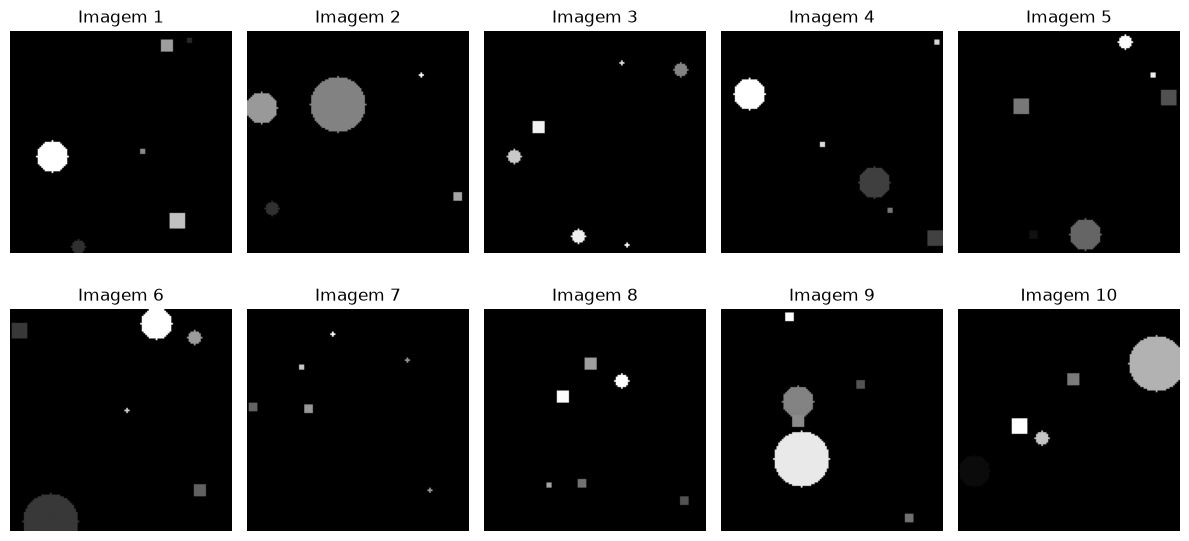

In [18]:
# Visualizar imagens
import matplotlib.pyplot as plt

linhas = 2
colunas = 5

fig, axes = plt.subplots(linhas, colunas, figsize=(12, 6))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(dataset):
        m, img = dataset[i]
        # Exibe a imagem com mapa de cores em escala de cinza
        ax.imshow(img, cmap='gray', origin='lower')
        ax.set_title(f"Imagem {i+1}")
        ax.axis('off')  # Oculta os eixos numéricos para ficar limpo
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

## Converter para Dataset do PyTorch

In [19]:
import torch
from torch.utils.data import Dataset, DataLoader

class DatasetImagens(Dataset):
    def __init__(self, imagens: np.array, mascaras: np.array):
        # adiciona dimensao do canal com unsqueeze (PyTroch requer essa dimensao)
        self.imagens = torch.from_numpy(imagens).double().unsqueeze(1)
        self.mascaras = torch.from_numpy(mascaras).double().unsqueeze(1)

    def __len__(self):
        return len(self.imagens)

    def __getitem__(self, index):
        return self.imagens[index], self.mascaras[index]
    
mascaras, imagens = map(np.array, zip(*dataset))

dados = DatasetImagens(imagens, mascaras)

dl = DataLoader(dados, batch_size=2, shuffle=True)

# validar shape do primeiro batch
imgs_batch1, masks_batch1 = next(iter(dl))
print(f"shapes {imgs_batch1[0].shape} (imagem) e {masks_batch1[0].shape} (mascara)")


shapes torch.Size([1, 128, 128]) (imagem) e torch.Size([1, 128, 128]) (mascara)


## Rede UNet

Como o objetivo é segmentação espacial, a rede precisa mapear a entrada para uma saída com a mesma resolução.

In [20]:
class SegImagemUnet(torch.nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = torch.nn.Conv2d(
            in_channels=1,
            out_channels=1,
            kernel_size=3,
            padding=1
        )
        self.relu1 = torch.nn.ReLU()

        # descida (contracao)
        self.pool1 = torch.nn.MaxPool2d(
            kernel_size=2
        )

        # bootleneck
        self.conv2 = torch.nn.Conv2d(
            in_channels=1,
            out_channels=1,
            kernel_size=3,
            padding=1
        )
        self.relu2 = torch.nn.ReLU()

        # subida (expansao)
        self.deconv1 = torch.nn.ConvTranspose2d(
            in_channels=1,
            out_channels=1,
            kernel_size=2,
            stride=2
        )

        # skip connection
        self.conv3 = torch.nn.Conv2d(
            in_channels=2,
            out_channels=1,
            kernel_size=3,
            padding=1
        )

    def forward(self, x):
        x1 = self.conv1(self.relu1(x))
        x_pool = self.pool1(x1)
        x_bottleneck = self.relu2(self.conv2(x_pool))
        x_up = self.deconv1(x_bottleneck)
        x_skip = torch.cat([x_up, x1], dim=1)
        saida = self.conv3(x_skip)
        return saida

# testar shape da saida da rede
modelo = SegImagemUnet()
entrada = imgs_batch1[0].float().unsqueeze(0) # adicione a dimensao de batch (1, 1, 128, 18)
saida = modelo.forward(entrada)
print(f"shape (entrada) = {entrada.shape}")
print(f"shape (saida) = {saida.shape}")
print(saida)

shape (entrada) = torch.Size([1, 1, 128, 128])
shape (saida) = torch.Size([1, 1, 128, 128])
tensor([[[[ 0.0274,  0.0444,  0.0439,  ...,  0.0450,  0.0444, -0.0950],
          [-0.0160,  0.0870,  0.0872,  ...,  0.0841,  0.0858, -0.0553],
          [-0.0165,  0.0861,  0.0860,  ...,  0.0834,  0.0842, -0.0620],
          ...,
          [-0.0149,  0.0864,  0.0837,  ...,  0.0823,  0.0840, -0.0589],
          [-0.0197,  0.0828,  0.0856,  ...,  0.0861,  0.0826, -0.0587],
          [-0.0442,  0.0668,  0.0678,  ...,  0.0649,  0.0643, -0.0165]]]],
       grad_fn=<ConvolutionBackward0>)


## Treinamento

In [21]:
otimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=0.001,
    betas=(0.99, 0.999)
)

loss_fn = torch.nn.BCEWithLogitsLoss()

historico_loss = []

# aumente conforme desejar
epochs=150

for epoch in range(epochs):
    loss_total = 0.0
    for img, mask in dl:
        # inferir mascara com modelo
        mask_pred = modelo.forward(
            img.float()
        )

        # calcular perda
        loss = loss_fn(mask_pred, mask)

        # zerar gradientes
        otimizador.zero_grad()

        # calcular derivada dos pesos
        loss.backward()

        # atualizar pesos
        otimizador.step()

        # acumular perda
        loss_total += loss.item()

    loss_media = loss_total/len(dl)

    if epoch % 10 == 0:
        print(f"epoch #{epoch}: BCE (Entropria Cruzada Binaria) = {loss_media}")
    historico_loss.append(loss_media)

epoch #0: BCE (Entropria Cruzada Binaria) = 1.9488861398492372
epoch #10: BCE (Entropria Cruzada Binaria) = 0.7306793509169227
epoch #20: BCE (Entropria Cruzada Binaria) = 0.674207715040423
epoch #30: BCE (Entropria Cruzada Binaria) = 0.5676166121502508
epoch #40: BCE (Entropria Cruzada Binaria) = 0.46303566009574465
epoch #50: BCE (Entropria Cruzada Binaria) = 0.37832114483672047
epoch #60: BCE (Entropria Cruzada Binaria) = 0.2878325249176579
epoch #70: BCE (Entropria Cruzada Binaria) = 0.2177397060443297
epoch #80: BCE (Entropria Cruzada Binaria) = 0.1605251868190863
epoch #90: BCE (Entropria Cruzada Binaria) = 0.1180699076830598
epoch #100: BCE (Entropria Cruzada Binaria) = 0.08856721225297728
epoch #110: BCE (Entropria Cruzada Binaria) = 0.06806405374582361
epoch #120: BCE (Entropria Cruzada Binaria) = 0.05489050607274078
epoch #130: BCE (Entropria Cruzada Binaria) = 0.045894014472054115
epoch #140: BCE (Entropria Cruzada Binaria) = 0.03967980314479584


## Testando o modelo

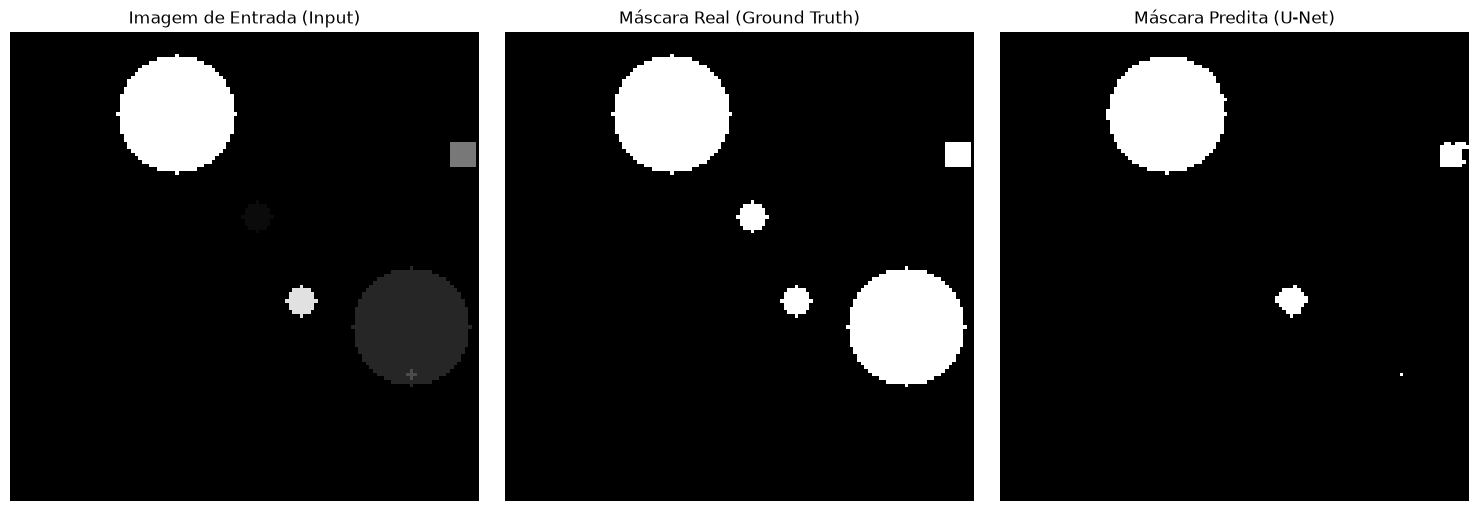

In [22]:
# Coloca o modelo em modo de avaliacao
modelo.eval()

# criar imagem de exemplo
mascara_teste, imagem_teste = gerar_mascara_imagem()

with torch.no_grad():
    # formata entrada com dimensoes esperadas pela rede
    entrada = torch.tensor(imagem_teste, dtype=torch.float32).reshape((1,1,N,N))

    # inferencia: saida eh com valores entre -1 e 1 (logits)
    pred_logits = modelo(entrada)

    # aplica sigmoide para converter os logits em probabilidades binarias
    pred_prob = torch.sigmoid(pred_logits)

    # remove as dimensoes de batch e canal para ficar com shape N x N
    mask_pred = pred_prob.squeeze().cpu().numpy()

    # threshold
    limiar = 0.9
    mask_pred_binaria = (mask_pred > limiar).astype(float)

# Visualizacao da inferencia da mascara
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(imagem_teste, cmap="gray", origin="lower")
axes[0].set_title("Imagem de Entrada (Input)")
axes[0].axis("off")

axes[1].imshow(mascara_teste, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Máscara Real (Ground Truth)")
axes[1].axis("off")

axes[2].imshow(mask_pred_binaria, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[2].set_title("Máscara Predita (U-Net)")
axes[2].axis("off")

plt.tight_layout()
plt.show()